In [1]:
import pandas as pd

In [2]:
df = pd.read_csv(r"C:\ProgramData\MySQL\MySQL Server 8.0\Uploads\Superstore_Sales_Data.csv")

In [3]:
df.head()

,order_id,order_date,city,category,product,quantity,sales,profit,payment_mode
0,101,1/5/2026,Ahmedabad,Furniture,Chair,2,5000,800,UPI
1,102,1/7/2026,Surat,Technology,Mouse,3,1500,300,Card
2,103,1/10/2026,Vadodara,Officce supplier,Pen,10,500,100,Cash
3,104,1/12/2026,Ahmedabad,Technology,Keybored,2,2500,600,UPI
4,105,1/15/2026,Surat,Furniture,Table,1,7000,-500,Card


In [4]:
df.shape

(10, 9)

In [5]:
df.columns

Index(['order_id', 'order_date', 'city', 'category', 'product', 'quantity',
       'sales', 'profit', 'payment_mode'],
      dtype='str')

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   order_id      10 non-null     int64
 1   order_date    10 non-null     str  
 2   city          10 non-null     str  
 3   category      10 non-null     str  
 4   product       10 non-null     str  
 5   quantity      10 non-null     int64
 6   sales         10 non-null     int64
 7   profit        10 non-null     int64
 8   payment_mode  10 non-null     str  
dtypes: int64(4), str(5)
memory usage: 852.0 bytes


In [7]:
df.isnull().sum()

order_id        0
order_date      0
city            0
category        0
product         0
quantity        0
sales           0
profit          0
payment_mode    0
dtype: int64

In [8]:
df.duplicated().sum()

np.int64(0)

In [9]:
df.dtypes

order_id        int64
order_date        str
city              str
category          str
product           str
quantity        int64
sales           int64
profit          int64
payment_mode      str
dtype: object

In [14]:
print(df.columns.tolist())

['order_id', 'order_date', 'city', 'category', 'product', 'quantity', 'sales', 'profit', 'payment_mode']


In [15]:
df["order_date"] = pd.to_datetime(df["order_date"])

In [16]:
df.dtypes

order_id                 int64
order_date      datetime64[us]
city                       str
category                   str
product                    str
quantity                 int64
sales                    int64
profit                   int64
payment_mode               str
dtype: object

In [18]:
df.describe()

,order_id,order_date,quantity,sales,profit
count,10.00000,10,10.000000,10.000000,10.000000
mean,105.50000,2026-01-16 04:48:00,3.700000,4550.000000,615.000000
min,101.00000,2026-01-05 00:00:00,1.000000,500.000000,-500.000000
25%,103.25000,2026-01-10 12:00:00,1.250000,1625.000000,262.500000
50%,105.50000,2026-01-16 12:00:00,2.000000,3750.000000,500.000000
75%,107.75000,2026-01-21 12:00:00,4.500000,6750.000000,950.000000
max,110.00000,2026-01-28 00:00:00,10.000000,12000.000000,2000.000000
std,3.02765,NaN,3.529243,3722.678247,685.585719


In [20]:
df["quantity"].describe()

count    10.000000
mean      3.700000
std       3.529243
min       1.000000
25%       1.250000
50%       2.000000
75%       4.500000
max      10.000000
Name: quantity, dtype: float64

In [21]:
df["sales"].describe()

count       10.000000
mean      4550.000000
std       3722.678247
min        500.000000
25%       1625.000000
50%       3750.000000
75%       6750.000000
max      12000.000000
Name: sales, dtype: float64

In [22]:
df["profit"].describe()

count      10.000000
mean      615.000000
std       685.585719
min      -500.000000
25%       262.500000
50%       500.000000
75%       950.000000
max      2000.000000
Name: profit, dtype: float64

In [26]:
df["total_amount"] = df["quantity"] * df["sales"]

In [27]:
df.head()

,order_id,order_date,city,category,product,quantity,sales,profit,payment_mode,total_amount
0,101,2026-01-05,Ahmedabad,Furniture,Chair,2,5000,800,UPI,10000
1,102,2026-01-07,Surat,Technology,Mouse,3,1500,300,Card,4500
2,103,2026-01-10,Vadodara,Officce supplier,Pen,10,500,100,Cash,5000
3,104,2026-01-12,Ahmedabad,Technology,Keybored,2,2500,600,UPI,5000
4,105,2026-01-15,Surat,Furniture,Table,1,7000,-500,Card,7000


In [28]:
df["revenue"] = df["quantity"] * df["sales"]

In [29]:
df[["order_id", "quantity", "sales", "revenue"]].head()

,order_id,quantity,sales,revenue
0,101,2,5000,10000
1,102,3,1500,4500
2,103,10,500,5000
3,104,2,2500,5000
4,105,1,7000,7000


In [30]:
total_revenue = df["revenue"].sum()
print("Total Revenue:", total_revenue)

Total Revenue: 94500


In [31]:
df["sales"]

0     5000
1     1500
2      500
3     2500
4     7000
5    12000
6     6000
7     1000
8     8000
9     2000
Name: sales, dtype: int64

In [32]:
df["revenue"] = df["quantity"] * df["sales"]

In [33]:
df[["order_id", "quantity", "sales", "revenue"]].head()

,order_id,quantity,sales,revenue
0,101,2,5000,10000
1,102,3,1500,4500
2,103,10,500,5000
3,104,2,2500,5000
4,105,1,7000,7000


In [34]:
# Create a month column
df["order_date"].dtype

dtype('<M8[us]')

In [35]:
df["order_date"] = pd.to_datetime(df["order_date"])
df["month"] = df["order_date"].dt.to_period("M")
monthly_revenue = df.groupby("month")["sales"].sum().sort_index()
print(monthly_revenue)

month
2026-01    45500
Freq: M, Name: sales, dtype: int64


In [37]:
import matplotlib.pyplot as plt 

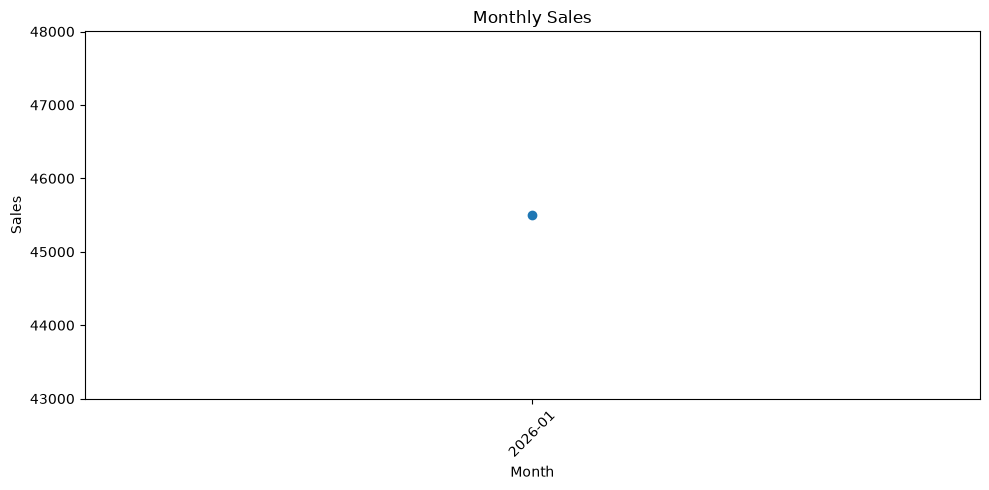

In [38]:
plt.figure(figsize=(10, 5))
plt.plot(monthly_revenue.index.astype(str), monthly_revenue.values, marker="o")
plt.title("Monthly Sales")
plt.xlabel("Month")
plt.ylabel("Sales")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [41]:
df["revenue"] = df["quantity"] * df["sales"]

category_revenue = df.groupby("category")["revenue"].sum().sort_values(ascending=False)

print(category_revenue)

category
Technology          41500
Furniture           23000
Office supplier     20000
Officce supplier    10000
Name: revenue, dtype: int64


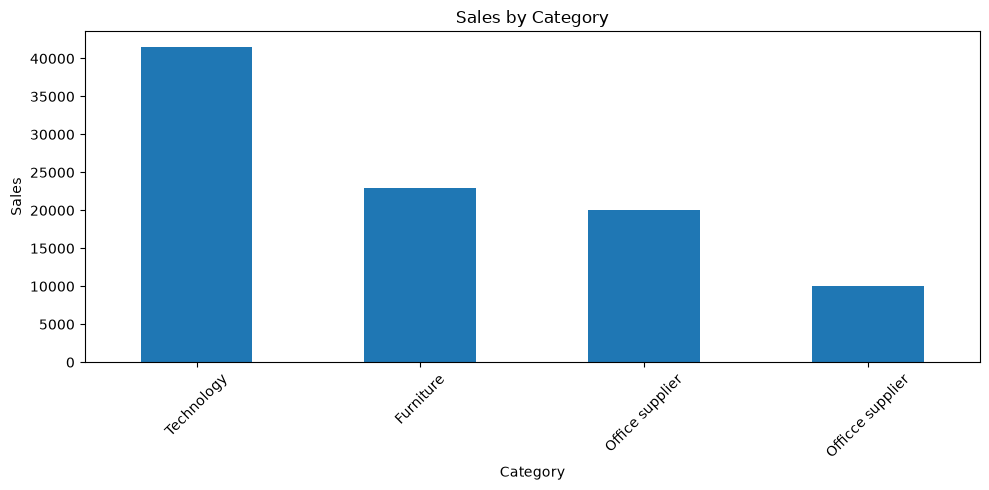

In [42]:
plt.figure(figsize=(10, 5))
category_revenue.plot(kind="bar")
plt.title("Sales by Category")
plt.xlabel("Category")
plt.ylabel("Sales")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [44]:
top_products = df.groupby("product")["revenue"].sum().sort_values(ascending=False).head(10)
print(top_products)

product
Moniter     24000
paper       20000
Chair       10000
Printer      8000
Table        7000
Desk         6000
Keybored     5000
Pen          5000
notebook     5000
Mouse        4500
Name: revenue, dtype: int64


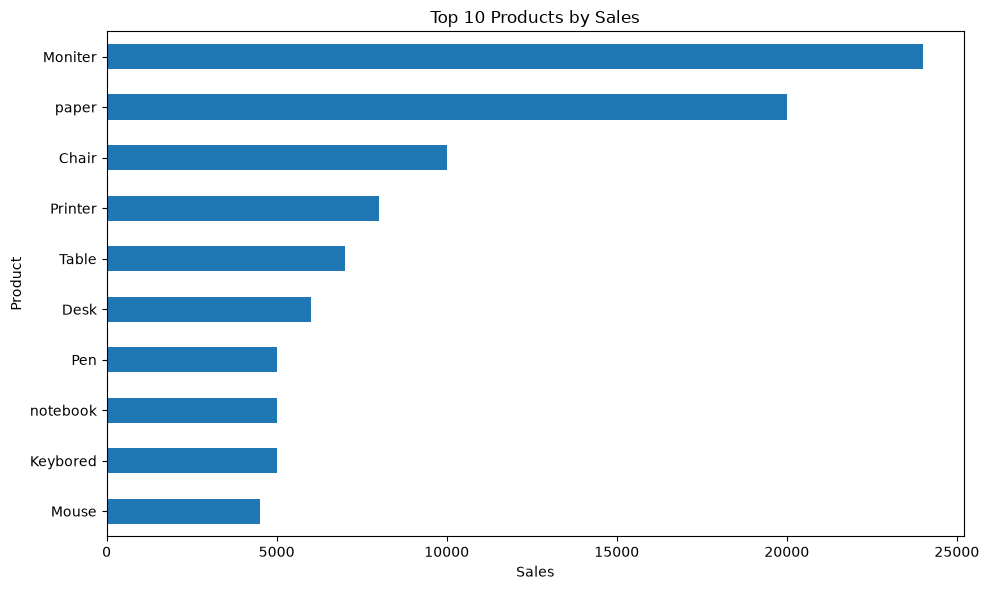

In [45]:
plt.figure(figsize=(10, 6))
top_products.sort_values().plot(kind="barh")
plt.title("Top 10 Products by Sales")
plt.xlabel("Sales")
plt.ylabel("Product")
plt.tight_layout()
plt.show()

In [48]:
city_sales = df.groupby("city")["sales"].sum().sort_values(ascending=False)
print(city_sales)

city
Surat        16500
Rajkot       14000
Ahmedabad     8500
Vadodara      6500
Name: sales, dtype: int64


In [49]:
top_cities = df.groupby("city")["sales"].sum().sort_values(ascending=False).head(10)

print(top_cities)

city
Surat        16500
Rajkot       14000
Ahmedabad     8500
Vadodara      6500
Name: sales, dtype: int64


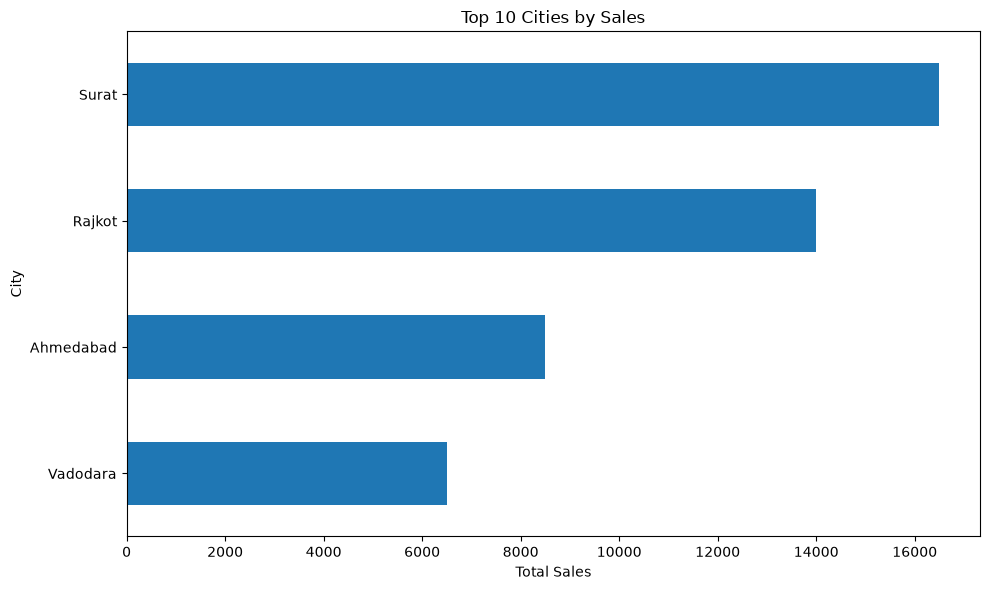

In [50]:
plt.figure(figsize=(10, 6))
top_cities.sort_values().plot(kind="barh")

plt.title("Top 10 Cities by Sales")
plt.xlabel("Total Sales")
plt.ylabel("City")

plt.tight_layout()
plt.show()

In [52]:
category_orders = df.groupby("category")["order_id"].count().sort_values(ascending=False)
print(category_orders.head(10))

category
Technology          4
Furniture           3
Officce supplier    2
Office supplier     1
Name: order_id, dtype: int64


In [55]:
repeat_categories = category_orders[category_orders > 1]
print("Repeat Categories:", len(repeat_categories))

Repeat Categories: 3


In [56]:
one_time_categories = category_orders[category_orders == 1]
print("One-Time Categories:", len(one_time_categories))

One-Time Categories: 1


In [57]:
category_type = {
    "One-Time Categories": len(one_time_categories),
    "Repeat Categories": len(repeat_categories)
}

print(category_type)

{'One-Time Categories': 1, 'Repeat Categories': 3}


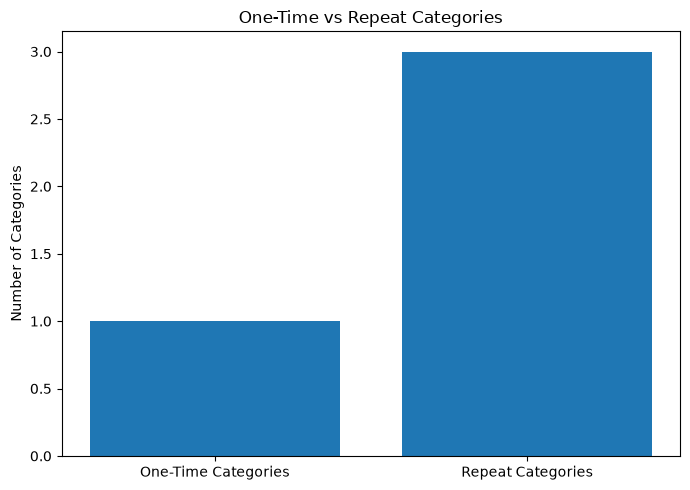

In [58]:
plt.figure(figsize=(7, 5))
plt.bar(
    category_type.keys(),
    category_type.values()
)

plt.title("One-Time vs Repeat Categories")
plt.ylabel("Number of Categories")

plt.tight_layout()
plt.show()

In [62]:
order_status = df["payment_mode"].value_counts()
print(order_status)

payment_mode
UPI     4
Card    3
Cash    3
Name: count, dtype: int64


In [63]:
order_status_percentage = (
    df["payment_mode"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print(order_status_percentage)

payment_mode
UPI     40.0
Card    30.0
Cash    30.0
Name: proportion, dtype: float64


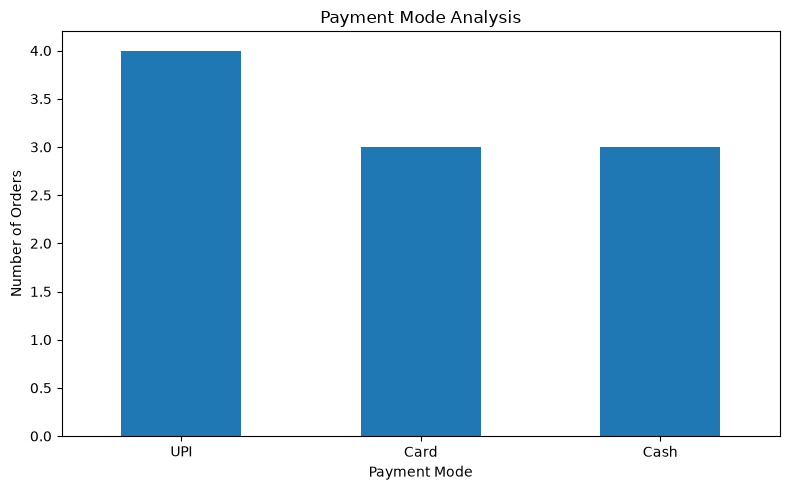

In [64]:
plt.figure(figsize=(8, 5))

order_status = df["payment_mode"].value_counts()
order_status.plot(kind="bar")

plt.title("Payment Mode Analysis")
plt.xlabel("Payment Mode")
plt.ylabel("Number of Orders")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

In [66]:
cancelled_orders = (df["payment_mode"] == "Cancelled").sum()
print("Cancelled Orders:", cancelled_orders)

Cancelled Orders: 0


In [67]:
total_orders = len(df)
print("Total Orders:", total_orders)

Total Orders: 10


In [68]:
cancellation_rate = (cancelled_orders / total_orders) * 100
print("Cancellation Rate:", round(cancellation_rate, 2), "%")

Cancellation Rate: 0.0 %


In [71]:
city_sales = df.groupby("city")["sales"].sum()
print(city_sales)

city
Ahmedabad     8500
Rajkot       14000
Surat        16500
Vadodara      6500
Name: sales, dtype: int64


In [72]:
top_cities = city_sales.head(10)
print(top_cities)

city
Ahmedabad     8500
Rajkot       14000
Surat        16500
Vadodara      6500
Name: sales, dtype: int64


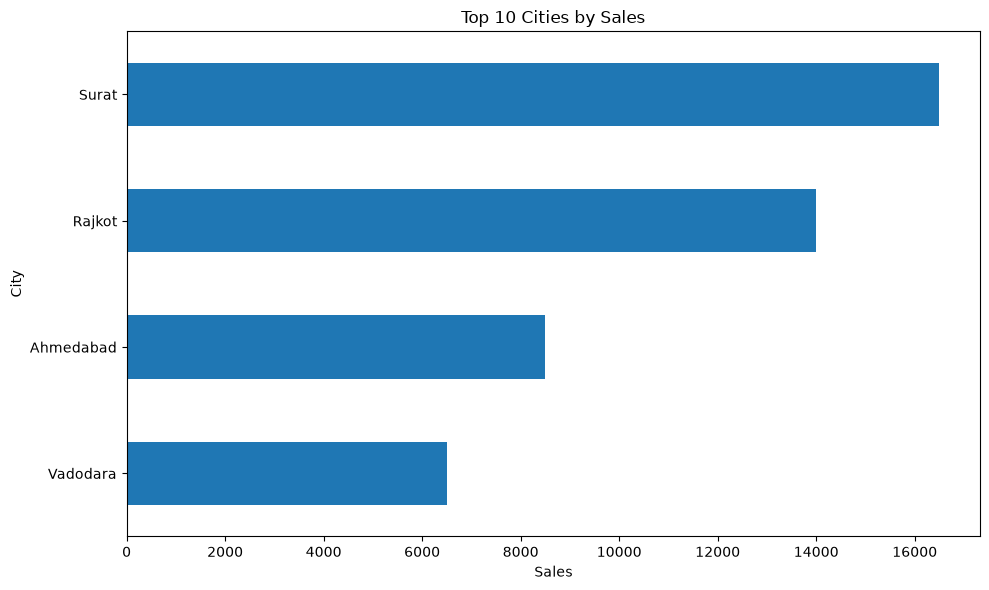

In [73]:
plt.figure(figsize=(10, 6))

top_cities.sort_values().plot(kind="barh")

plt.title("Top 10 Cities by Sales")
plt.xlabel("Sales")
plt.ylabel("City")

plt.tight_layout()
plt.show()

In [75]:
payment_revenue = (
    df.groupby("payment_mode")["sales"]
    .sum()
    .sort_values(ascending=False)
)

print(payment_revenue)

payment_mode
UPI     27500
Card     9500
Cash     8500
Name: sales, dtype: int64


In [76]:
payment_percentage = (
    payment_revenue / payment_revenue.sum() * 100
).round(2)

print(payment_percentage)

payment_mode
UPI     60.44
Card    20.88
Cash    18.68
Name: sales, dtype: float64


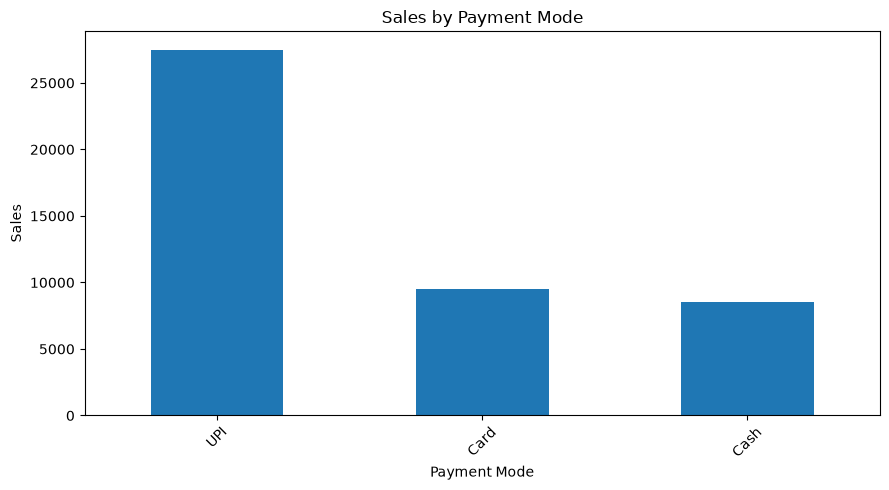

In [77]:
plt.figure(figsize=(9, 5))

payment_revenue.plot(kind="bar")

plt.title("Sales by Payment Mode")
plt.xlabel("Payment Mode")
plt.ylabel("Sales")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [79]:
total_revenue = df["sales"].sum()
total_orders = df["order_id"].nunique()
total_units = df["quantity"].sum()

average_order_value = total_revenue / total_orders

print("Total Revenue:", total_revenue)
print("Total Orders:", total_orders)
print("Total Units:", total_units)
print("Average Order Value:", round(average_order_value, 2))

Total Revenue: 45500
Total Orders: 10
Total Units: 37
Average Order Value: 4550.0


In [80]:
print("===== SUPERSTORE SALES SUMMARY =====")
print("Total Revenue:", round(total_revenue, 2))
print("Total Orders:", total_orders)
print("Total Units Sold:", total_units)
print("Average Order Value:", round(average_order_value, 2))

===== SUPERSTORE SALES SUMMARY =====
Total Revenue: 45500
Total Orders: 10
Total Units Sold: 37
Average Order Value: 4550.0
